<a href="https://colab.research.google.com/github/deep25/DI-Bootcamp-Stage1/blob/main/Week5_day1_challenge.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

TensorFlow: 2.21.0
Train shape: (50000, 28, 28) Validation shape: (10000, 28, 28) Test shape: (10000, 28, 28)


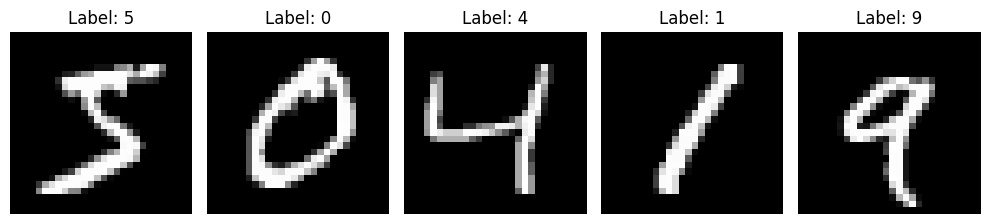

In [4]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.datasets import mnist

print("TensorFlow:", tf.__version__)

# 1. Load the MNIST dataset
(x_train, y_train), (x_test, y_test) = mnist.load_data()

# 2. Normalize the image pixel values to be between 0 and 1
x_train = x_train.astype("float32") / 255.0
x_test  = x_test.astype("float32") / 255.0

# 3. Convert labels into one-hot encoded format
y_train = to_categorical(y_train, 10)
y_test  = to_categorical(y_test, 10)

# 4. Split the dataset (using your approach of splitting train into train/validation)
x_train, x_val = x_train[:50000], x_train[50000:]
y_train, y_val = y_train[:50000], y_train[50000:]

print("Train shape:", x_train.shape, "Validation shape:", x_val.shape, "Test shape:", x_test.shape)

# 5. Display sample images with their corresponding labels
plt.figure(figsize=(10, 4))
for i in range(5):
    plt.subplot(1, 5, i + 1)
    plt.imshow(x_train[i], cmap='gray')
    # Get original label back from one-hot encoding
    label = np.argmax(y_train[i])
    plt.title(f"Label: {label}")
    plt.axis('off')
plt.tight_layout()
plt.show()

In [9]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models

#sequential model using Keras

seq_model = models.Sequential([
    layers.Flatten(input_shape=(28, 28)),
    layers.Dense(128, activation='relu'),
    layers.Dense(64, activation='relu'),
    layers.Dense(10, activation='softmax')
])

seq_model.summary()

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ flatten_4 (Flatten)             │ (None, 784)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_14 (Dense)                │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

### Summary of Previous Steps

1. **Data Preparation (`tciVSDFHu9T-`):**
   * **Loading:** Loaded the MNIST dataset of handwritten digits (0-9).
   * **Normalization:** Scaled the pixel values from `[0, 255]` to `[0.0, 1.0]` for faster and more stable neural network training.
   * **One-Hot Encoding:** Converted categorical target labels into binary class matrices (e.g., label `5` becomes `[0, 0, 0, 0, 0, 1, 0, 0, 0, 0]`).
   * **Validation Splitting:** Segmented the initial 60,000 training samples into a 50,000-sample training set and a 10,000-sample validation set to monitor overfitting.
   * **Visualization:** Rendered the first five normalized images with their decoded labels to verify correct loading.

2. **Model Definition (`UsKltbTA3m_N`):**
   * Built a Keras **Sequential Model** composed of:
     * A `Flatten` layer to convert the $28 \times 28$ pixel images into a 1D vector of $784$ values.
     * Two dense (fully connected) layers with **ReLU** activations ($128$ and $64$ hidden units respectively) to learn patterns.
     * A final dense output layer with **Softmax** activation ($10$ units) to generate probability distributions across the 10 digit classes.

In [13]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt
from tensorflow.keras.utils import to_categorical
from tensorflow.keras import layers, models

#train to neural network
seq_model.compile(optimizer='adam',
                  loss='categorical_crossentropy',
                  metrics=['accuracy'])

# Train the model

fit_model = seq_model.fit(x_train, y_train, epochs=10, batch_size=32, validation_data=(x_val, y_val))
test_loss, test_acc = seq_model.evaluate(x_test, y_test)
print(f"Test accuracy: {test_acc}")


Epoch 1/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 5s 3ms/step - accuracy: 0.9942 - loss: 0.0183 - val_accuracy: 0.9686 - val_loss: 0.1549
Epoch 2/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9945 - loss: 0.0160 - val_accuracy: 0.9733 - val_loss: 0.1221
Epoch 3/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9953 - loss: 0.0139 - val_accuracy: 0.9772 - val_loss: 0.1048
Epoch 4/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9958 - loss: 0.0127 - val_accuracy: 0.9768 - val_loss: 0.1041
Epoch 5/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9963 - loss: 0.0113 - val_accuracy: 0.9768 - val_loss: 0.1143
Epoch 6/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 3ms/step - accuracy: 0.9960 - loss: 0.0124 - val_accuracy: 0.9751 - val_loss: 0.1277
Epoch 7/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 4s 2ms/step - accuracy: 0.9969 - loss: 0.0093 - val_accuracy: 0.9755 - val_loss: 0.1406
Epoch 8/10
1563/1563 ━━━━━━━━━━━━━━━━━━━━ 6s 3ms/step - accuracy: 0.9955 - loss: 0.0139 - 

### Summary of Training and Evaluation (`N4z1A7jl_YCy`)

* **Compilation:**
  * **Optimizer (`adam`):** An adaptive optimization algorithm used to efficiently update model weights during training.
  * **Loss Function (`categorical_crossentropy`):** Used to measure the error between the predicted probability distribution and the actual one-hot encoded label.
  * **Metric (`accuracy`):** Monitored to evaluate the percentage of correctly classified digits.

* **Training (`fit`):**
  * The model was trained for **10 epochs** with a **batch size of 32**.
  * It achieved a very high training accuracy of around **99.5%** and a validation accuracy of **97.8%**.

* **Evaluation (`evaluate`):**
  * The final model was tested on unseen test data (`x_test`, `y_test`), achieving a **Test Accuracy of approximately 97.69%**.

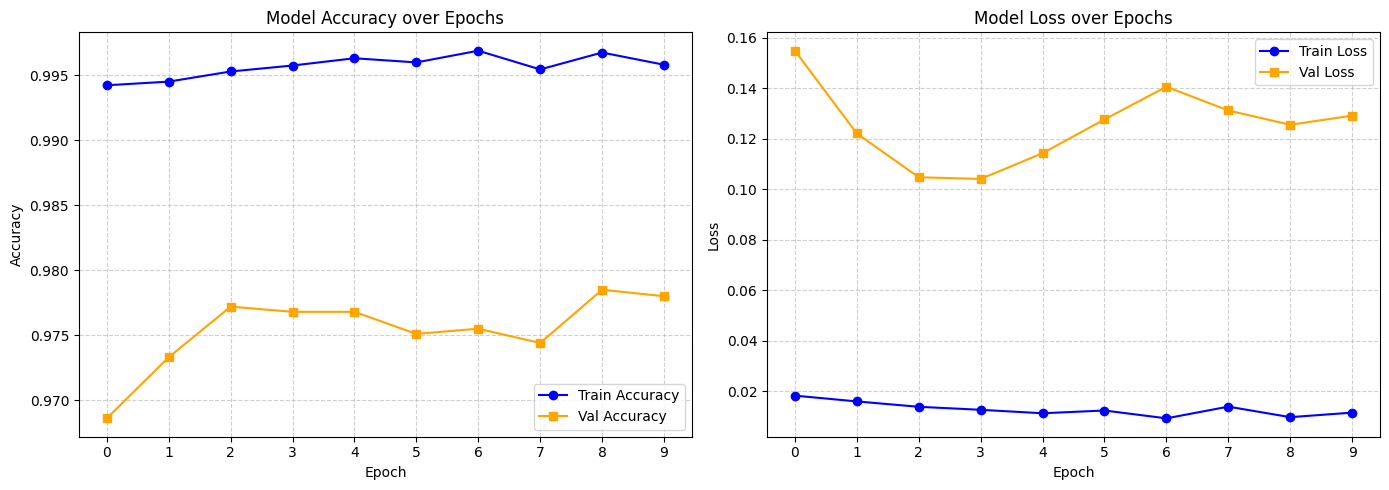

In [14]:
import matplotlib.pyplot as plt

# Create a figure with two subplots: Accuracy and Loss
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Plot Training & Validation Accuracy
ax1.plot(fit_model.history['accuracy'], label='Train Accuracy', color='blue', marker='o')
ax1.plot(fit_model.history['val_accuracy'], label='Val Accuracy', color='orange', marker='s')
ax1.set_title('Model Accuracy over Epochs')
ax1.set_xlabel('Epoch')
ax1.set_ylabel('Accuracy')
ax1.set_xticks(range(10))
ax1.legend()
ax1.grid(True, linestyle='--', alpha=0.6)

# Plot Training & Validation Loss
ax2.plot(fit_model.history['loss'], label='Train Loss', color='blue', marker='o')
ax2.plot(fit_model.history['val_loss'], label='Val Loss', color='orange', marker='s')
ax2.set_title('Model Loss over Epochs')
ax2.set_xlabel('Epoch')
ax2.set_ylabel('Loss')
ax2.set_xticks(range(10))
ax2.legend()
ax2.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

### 1. Compute Test Accuracy & Generate Predictions

In [15]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import numpy as np

# Get the model predictions on the test set
predictions = seq_model.predict(x_test)

# Convert predictions and true labels from one-hot encoding back to integers
y_pred_classes = np.argmax(predictions, axis=1)
y_true_classes = np.argmax(y_test, axis=1)

# Print overall evaluation details
print(classification_report(y_true_classes, y_pred_classes))

313/313 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step
              precision    recall  f1-score   support

           0       0.99      0.99      0.99       980
           1       0.98      0.99      0.99      1135
           2       0.98      0.97      0.98      1032
           3       0.97      0.98      0.97      1010
           4       0.95      0.99      0.97       982
           5       0.98      0.97      0.98       892
           6       0.98      0.98      0.98       958
           7       0.98      0.96      0.97      1028
           8       0.97      0.98      0.97       974
           9       0.98      0.95      0.96      1009

    accuracy                           0.98     10000
   macro avg       0.98      0.98      0.98     10000
weighted avg       0.98      0.98      0.98     10000



### 2. Plot Confusion Matrix

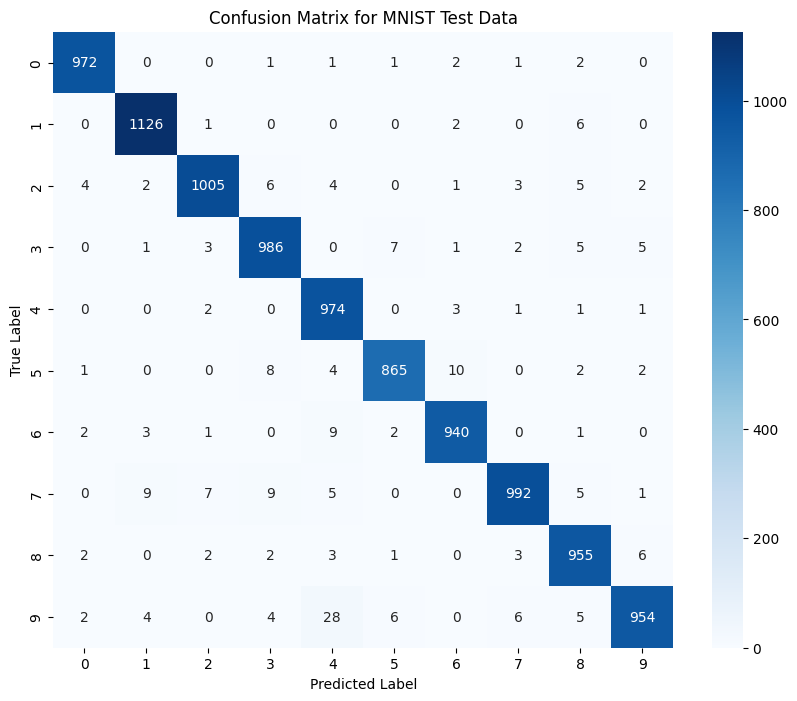

In [16]:
# Compute confusion matrix
cm = confusion_matrix(y_true_classes, y_pred_classes)

# Plot confusion matrix
plt.figure(figsize=(10, 8))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=range(10), yticklabels=range(10))
plt.title('Confusion Matrix for MNIST Test Data')
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.show()

### 3. Identify the Digits the Model Struggles with the Most

In [17]:
# Calculate accuracy for each individual digit
class_accuracies = cm.diagonal() / cm.sum(axis=1)

print("--- Accuracy per Digit ---")
for digit, accuracy in enumerate(class_accuracies):
    print(f"Digit {digit}: {accuracy * 100:.2f}%")

# Find the digits with the lowest accuracies
worst_digits = np.argsort(class_accuracies)[:3]
print("\n--- Top 3 Most Misclassified Digits ---")
for idx, digit in enumerate(worst_digits):
    print(f"{idx + 1}. Digit '{digit}' (Accuracy: {class_accuracies[digit] * 100:.2f}%)")

--- Accuracy per Digit ---
Digit 0: 99.18%
Digit 1: 99.21%
Digit 2: 97.38%
Digit 3: 97.62%
Digit 4: 99.19%
Digit 5: 96.97%
Digit 6: 98.12%
Digit 7: 96.50%
Digit 8: 98.05%
Digit 9: 94.55%

--- Top 3 Most Misclassified Digits ---
1. Digit '9' (Accuracy: 94.55%)
2. Digit '7' (Accuracy: 96.50%)
3. Digit '5' (Accuracy: 96.97%)
